# Boletín de ejercicios con matplotlib

Vamos a utilizar en todos los ejercicios el csv subido a Blackboard con datos de sensores industriales ("sensores_industriales.csv") como nuestro dataset para estas actividades.

**Nota:** coloca el CSV adjunto en la misma carpeta que este cuaderno.

## Ejercicio 1

Realiza lo siguiente:
- Muestra las cinco primeras filas
- Muestra las tres ultimas filas de datos
- ¿Cuál es la dimensión del dataset?
- Indica los nombres de las columnas del dataset.
- Indica cuántas filas y columnas tiene.

In [1]:
# Cargamos el dataset y exploramos su estructura.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("sensores_industriales(2).csv")
display(df.head())
display(df.tail(3))
print("Dimensión:", df.shape)
print("Columnas:", df.columns.tolist())
print("Filas:", df.shape[0], "| Columnas:", df.shape[1])

,fecha,sensor,zona,turno,temperatura,humedad,consumo,vibración,presión,estado
0,2026-10-01 08:00,S01,Producción,Mañana,35.7,60.3,154.7,1.36,1.87,Normal
1,2026-10-01 09:00,S02,Almacén,Mañana,38.0,60.9,171.4,1.64,2.01,Normal
2,2026-10-01 10:00,S03,Laboratorio,Mañana,42.7,61.6,177.4,2.00,2.12,Normal
3,2026-10-01 11:00,S04,Producción,Mañana,43.6,52.0,193.8,2.29,2.24,Normal
4,2026-10-01 12:00,S05,Almacén,Mañana,45.7,59.3,201.9,2.25,2.35,Normal


,fecha,sensor,zona,turno,temperatura,humedad,consumo,vibración,presión,estado
117,2026-10-06 05:00,S10,Producción,Noche,55.1,53.3,211.2,2.68,2.32,Alerta
118,2026-10-01 15:00,S08,Almacén,Mañana,50.8,56.1,203.9,2.93,1.99,Normal
119,2026-10-03 08:00,S01,Producción,Mañana,38.8,59.3,165.1,1.24,1.87,Normal


Dimensión: (120, 10)
Columnas: ['fecha', 'sensor', 'zona', 'turno', 'temperatura', 'humedad', 'consumo', 'vibración', 'presión', 'estado']
Filas: 120 | Columnas: 10


## Ejercicio 2

Empecemos con la EDA. Realiza lo siguiente:
- Comprueba los tipos de datos del dataset
- ¿Hay valores ausentes por columna? Indica cuántas.
- Averigua cuántas filas completas estan duplicadas.

In [2]:
# Revisamos tipos, valores ausentes y duplicados.
print(df.dtypes)
print("\nValores ausentes por columna:")
print(df.isna().sum())
print("Filas duplicadas:", df.duplicated().sum())

fecha           object
sensor          object
zona            object
turno           object
temperatura    float64
humedad        float64
consumo        float64
vibración      float64
presión        float64
estado          object
dtype: object

Valores ausentes por columna:
fecha          0
sensor         0
zona           0
turno          0
temperatura    0
humedad        2
consumo        1
vibración      1
presión        0
estado         0
dtype: int64
Filas duplicadas: 2


## Ejercicio 3

Muestra los siguiente datos del dataset:
- El valor medio de consumo
- La temperatura mínima
- La humedad máxima
NOTA: todos los valores debes mostrarlos redondeados a dos decimales.

In [3]:
# Pandas ignora los valores ausentes en estos cálculos.
print(f"Consumo medio: {df['consumo'].mean():.2f}")
print(f"Temperatura mínima: {df['temperatura'].min():.2f}")
print(f"Humedad máxima: {df['humedad'].max():.2f}")

Consumo medio: 193.45
Temperatura mínima: 35.20
Humedad máxima: 64.90


## Ejercicio 4

Realiza:
- Cuenta los registros de cada estado
- Enumera el número de registros de cada zona.
- ¿Cuántas zonas hay diferentes?
- ¿Cuántos sensores tienen un nombre diferente?

In [4]:
# Contamos las apariciones y los valores diferentes.
print("Registros por estado:")
print(df["estado"].value_counts())
print("\nRegistros por zona:")
print(df["zona"].value_counts())
print("Zonas diferentes:", df["zona"].nunique())
print("Sensores diferentes:", df["sensor"].nunique())

Registros por estado:
estado
Normal    101
Alerta     19
Name: count, dtype: int64

Registros por zona:
zona
Producción     41
Almacén        40
Laboratorio    39
Name: count, dtype: int64
Zonas diferentes: 3
Sensores diferentes: 12


## Ejercicio 5

Muestra las lecturas de senrores que estén en estado Alerta y cuya temperatura supere los 55 grados. Estos datos mostrados deben ser la fecha, el nombre del sensor, la temperatura y el consumo.
¿Cuántos registros hay en esa muestra?

In [5]:
# Combinamos las dos condiciones con &.
muestra = df.loc[(df["estado"] == "Alerta") & (df["temperatura"] > 55),
                 ["fecha", "sensor", "temperatura", "consumo"]]
display(muestra)
print("Número de registros:", len(muestra))

,fecha,sensor,temperatura,consumo
21,2026-10-02 05:00,S10,55.6,207.4
23,2026-10-02 07:00,S12,55.8,227.6
70,2026-10-04 06:00,S11,56.2,210.3
71,2026-10-04 07:00,S12,58.5,231.1
82,2026-10-04 18:00,S11,55.4,204.3
95,2026-10-05 07:00,S12,57.4,232.0
106,2026-10-05 18:00,S11,57.4,213.1
107,2026-10-05 19:00,S12,55.2,218.7
117,2026-10-06 05:00,S10,55.1,211.2


Número de registros: 9


## Ejercicio 6.

Representa la temperatura del sensor S01 durante sus lecturas, ordenadas por fecha. Incluye marcadores, título, etiquetas, cuadrícula y leyenda.

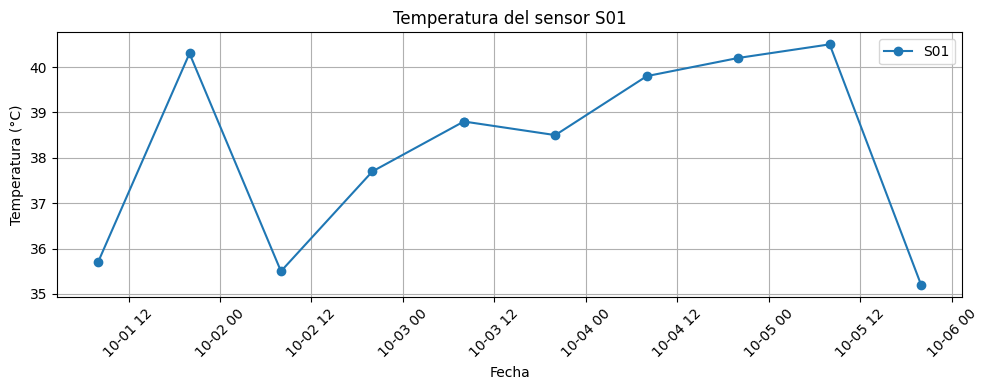

In [6]:
# Convertimos las fechas y ordenamos las lecturas del sensor.
s01 = df[df["sensor"] == "S01"].copy()
s01["fecha"] = pd.to_datetime(s01["fecha"])
s01 = s01.sort_values("fecha")

plt.figure(figsize=(10, 4))
plt.plot(s01["fecha"], s01["temperatura"], marker="o", label="S01")
plt.title("Temperatura del sensor S01")
plt.xlabel("Fecha")
plt.ylabel("Temperatura (°C)")
plt.xticks(rotation=45)
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()

## Ejercicio 7

Cuenta cuantas lecturas en estado Alerta hay por zona. Representa el resultado mediante barras con el valor encima de cada una de ellas, empleando las etiquetas de ejes y titulo. Asegúrate que se ven bien los valores representados y en caso contrario usa xlim() o ylim().

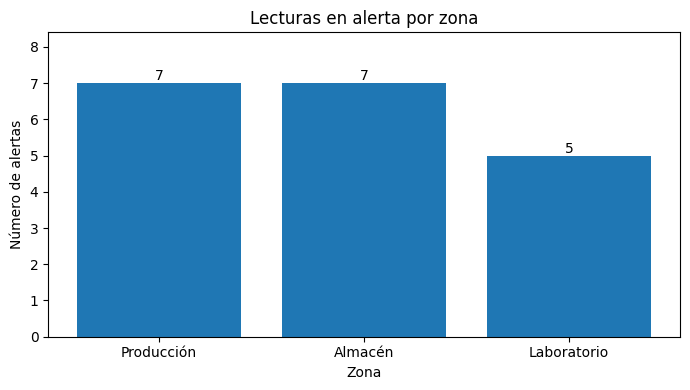

In [ ]:
# Contamos las alertas de cada zona.
alertas = df[df["estado"] == "Alerta"]["zona"].value_counts()
plt.figure(figsize=(7, 4))
plt.bar(alertas.index, alertas.values)
for i, valor in enumerate(alertas.values):
    plt.text(i, valor, str(valor), ha="center", va="bottom")
plt.ylim(0, max(alertas.max() * 1.2, 1))
plt.xlabel("Zona")
plt.ylabel("Número de alertas")
plt.title("Lecturas en alerta por zona")
plt.tight_layout()
plt.show()

## Ejercicio 8

Construye un histograma de temperatura con 8 intervalos. Añade titulo, etiquetas y cuadricula horizontal (añade algo de transparencia).

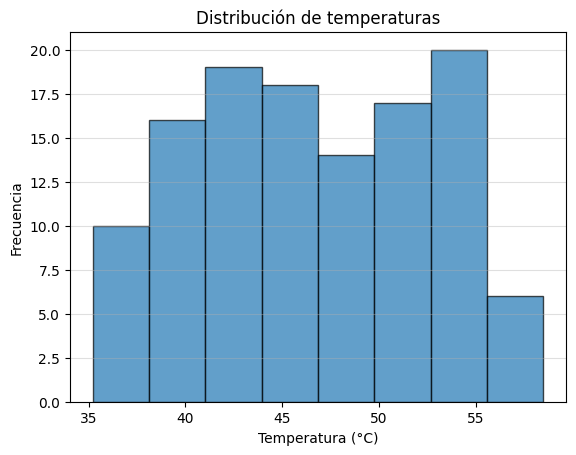

In [ ]:
# Eliminamos temperaturas ausentes antes de representar.
plt.hist(df["temperatura"].dropna(), bins=8, alpha=0.7, edgecolor="black")
plt.title("Distribución de temperaturas")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Frecuencia")
plt.grid(axis="y", alpha=0.4)
plt.show()

## Ejercicio 9

Representa temperatura frente a consumo. Descarta aquellas filas que no tengan consumo o temperatura. Calcula una recta de regresion, dibújala y muestra su ecuación. Luego haz una estimación de cómo sería el consumo para una temperatura de 50 °C a partir de esa expresión matemática.

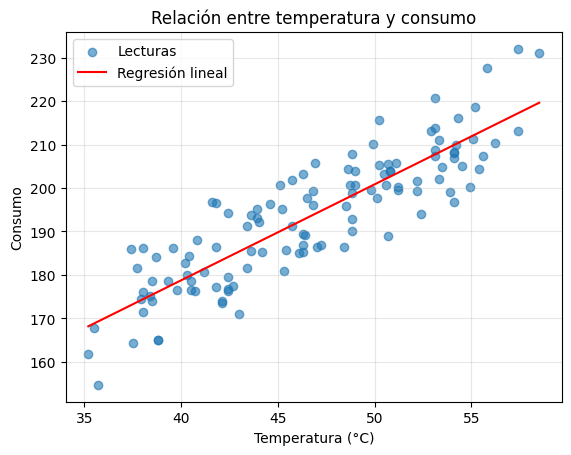

Ecuación: y = 2.2076x +90.4750
Consumo estimado a 50 °C: 200.86


In [9]:
# Eliminamos las filas que no tienen ambos valores.
datos = df.dropna(subset=["temperatura", "consumo"])
x = datos["temperatura"]
y = datos["consumo"]

# polyfit con grado 1 obtiene la pendiente y la ordenada.
m, b = np.polyfit(x, y, 1)
x_recta = np.linspace(x.min(), x.max(), 100)
plt.scatter(x, y, alpha=0.6, label="Lecturas")
plt.plot(x_recta, m * x_recta + b, color="red", label="Regresión lineal")
plt.title("Relación entre temperatura y consumo")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Consumo")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Ecuación: y = {m:.4f}x {b:+.4f}")
print(f"Consumo estimado a 50 °C: {m * 50 + b:.2f}")

## Ejercicio 10

Representa mediante un histograma la distribución de temperaturas registradas por los sensores. Añade un título, etiquetas de ejes, etc. y guarda el gráfico en formato png antes de mostrarlo.

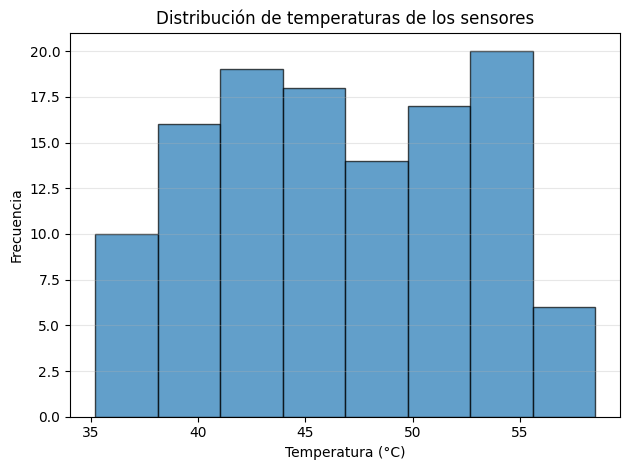

In [10]:
# Guardamos el histograma antes de mostrarlo.
plt.hist(df["temperatura"].dropna(), bins=8, edgecolor="black", alpha=0.7)
plt.title("Distribución de temperaturas de los sensores")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Frecuencia")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("histograma_temperaturas.png", dpi=150)
plt.show()